# M5 · Leave-one-generator-out

**M4 result** (video AUC %, deployed model = θ_s, 10 epochs). Train on DF, F2F, FS, NT. FaceShifter unseen.

| λ | seen | NT | FaceShifter | what the offsets did |
|---|---|---|---|---|
| ∞ (pooled, same code) | 96.41 | 87.90 | 90.53 | offsets stay 0 |
| 1 | 96.06 | 86.49 | 92.06 | tiny offsets |
| 0.1 | 95.66 | 84.90 | 92.48 | |
| **0.01** | 95.55 | 85.06 | **92.91** | best unseen |
| 0.001 | 93.27 | 76.25 | 86.35 | offsets too large |
| 0 | 90.14 | 67.69 | 80.04 | four separate models |

References on FaceShifter: M1 pooled 88.19, best single generator (train on FS) 89.56. λ = 0.01 beats both.

**Read this before comparing to M1.** λ = ∞ already scores 90.53 on FaceShifter, not 88.19. About 2.3 points come from M4's training order (one generator per batch, fixed 1/G real split), not from the offsets. The offset itself is the gap from λ = ∞ to λ = 0.01: **+2.4 on FaceShifter**, with −0.9 on seen generators and −2.8 on NeuralTextures. That is the comparison M5 repeats.

**M5.** Same training for every held-out generator in {DF, F2F, FS, NT, FaceShifter}. Two runs each: λ = ∞ and λ = 0.01. The FaceShifter fold is the M4 run; it is loaded, not trained again. Eight new runs, about 10–14 h, resumable.

| Section | What it does | Run time |
|---|---|---|
| 1–3 | settings, all 6 categories in RAM, detector | ~2 min |
| 4.2 | same GBLA checks as M4 | ~1 min |
| 4.3 | 4 held-out generators × 2 λ | ~10–14 h |
| 5 | LOGO table | minutes |

## 1. Setup

### 1.1 Settings

`FOLDS` is the held-out generator, in run order. FaceShifter is last because its two runs already exist in `runs/m4/`.

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M5_DIR = RUNS_ROOT / "m5"
M4_DIR = RUNS_ROOT / "m4"

ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}

ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
EPOCHS = 10
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
LR_MAX, LR_MIN = 3e-4, 1e-5
SEED = 0

# held-out generator, in run order. FaceShifter is reused from M4.
FOLDS = ["NeuralTextures", "FaceSwap", "Deepfakes", "Face2Face", "FaceShifter"]
LAMBDAS = [float("inf"), 0.01]

VAL_FRAMES_PER_VIDEO = 8
CACHE_IN_RAM = True
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

M1_RUN_DIR = RUNS_ROOT / "m1" / f"lnclip_{ARCH}_train-DF-F2F-FS-NT_seed{SEED}"
assert INDEX_CSV.exists(), f"index not found: {INDEX_CSV}"
M5_DIR.mkdir(parents=True, exist_ok=True)
print("M5 runs go to:", M5_DIR)

M5 runs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m5


### 1.2 Imports and environment

In [2]:
# 1.2 Imports and environment
import json, math, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M5 needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    candidates = []
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        candidates.append(int(meminfo["MemAvailable"].split()[0]) * 1024)
    except (OSError, KeyError, ValueError):
        pass
    return min(candidates) / 1e9 if candidates else 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))
torch.set_num_threads(2)
pd.Series({
    "torch": torch.__version__, "open_clip": open_clip.__version__,
    "GPU": torch.cuda.get_device_name(0),
    "CPUs usable by this job": CPUS, "data loader workers": NUM_WORKERS,
    "free RAM for this job (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB
CPUs usable by this job,8
data loader workers,7
free RAM for this job (GB),1051.5


## 2. Data

### 2.1 Index

Train crops for **all five** generators are loaded, because every generator is held out of one fold and trained on in the others. Test is always real + all five generators.

In [3]:
# 2.1 Index
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


def subsample_frames(df):
    frames_per_video = int(df.groupby(["generator", "video_id"]).size().max())
    keep_every = max(1, frames_per_video // VAL_FRAMES_PER_VIDEO)
    rank = df.groupby(["generator", "video_id"]).frame_idx.rank(method="first").astype(int) - 1
    return df[rank % keep_every == 0].reset_index(drop=True)


full_train = subset("train", ALL_GENERATORS)
full_val = subsample_frames(subset("val", ALL_GENERATORS))
test_df = subset("test", ALL_GENERATORS)
display(pd.DataFrame({
    "train": full_train.groupby("generator").size().reindex(CATEGORIES),
    "val": full_val.groupby("generator").size().reindex(CATEGORIES),
    "test": test_df.groupby("generator").size().reindex(CATEGORIES),
}).fillna(0).astype(int))

,train,val,test
generator,,,
original,23040,1120,4480
Deepfakes,23040,1120,4480
Face2Face,23040,1120,4480
FaceSwap,23040,1120,4480
NeuralTextures,23040,1120,4480
FaceShifter,23040,1120,4480


### 2.2 Crops in RAM

Train is 138,240 crops (20.8 GB). Val and test are the same size as a single M4 load.

In [4]:
# 2.2 Crops in RAM
def load_images(df, desc):
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", full_train), ("val", full_val), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} crops -> RAM")
        budget -= need
        print(f"{name}: {len(df):,} crops, {need:.1f} GB, {(time.time() - t) / 60:.1f} min")
    else:
        images[name] = None
        print(f"{name}: read from disk (needs {need:.1f} GB, budget left {budget:.1f} GB)")

train crops -> RAM: 100%|██████████| 138240/138240 [01:20<00:00, 1724.30it/s]


train: 138,240 crops, 20.8 GB, 1.4 min


val crops -> RAM: 100%|██████████| 6720/6720 [00:03<00:00, 1743.36it/s]


val: 6,720 crops, 1.0 GB, 0.1 min


test crops -> RAM: 100%|██████████| 26880/26880 [00:15<00:00, 1733.52it/s]

test: 26,880 crops, 4.0 GB, 0.3 min


### 2.3 Fold sampler

`setup_fold(held_out)` points the sampler at the other four generators. Reals are split round-robin across those four, disjointly. Every fold is 900 steps, the same budget as M4.

In [5]:
# 2.3 Fold sampler
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    def __init__(self, df, train, imgs=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = imgs
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class RoundRobinSampler(Sampler):
    def __init__(self, df, seed):
        self.df_gen = df.generator.values
        self.real_idx = np.flatnonzero(self.df_gen == "original")
        self.seed = seed
        self.epoch = 0
        self.gens = []
        self.blocks = {}
        self.n = 0

    def set_fold(self, gens):
        self.gens = list(gens)
        gcount = len(self.gens)
        self.blocks = {}
        for k, g in enumerate(self.gens):
            fakes = np.flatnonzero(self.df_gen == g)
            reals = self.real_idx[k::gcount][: len(fakes) // gcount]
            self.blocks[g] = (fakes, reals)
        self.n = sum(len(a) + len(b) for a, b in self.blocks.values())

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        order = np.random.default_rng([self.seed, self.epoch, 1])
        gens = list(self.gens)
        order.shuffle(gens)
        out = []
        for g in gens:
            fakes, reals = self.blocks[g]
            rng = np.random.default_rng([self.seed, ALL_GENERATORS.index(g), self.epoch])
            out.extend(rng.permutation(np.concatenate([fakes, reals])).tolist())
        return iter(out)

    def __len__(self):
        return self.n


TRAIN_GENERATORS = []


def slice_mask(df, gens):
    return df.generator.isin(["original", *gens]).values


def setup_fold(held_out):
    global TRAIN_GENERATORS
    TRAIN_GENERATORS = [g for g in ALL_GENERATORS if g != held_out]
    train_sampler.set_fold(TRAIN_GENERATORS)
    assert train_sampler.n == 115_200, train_sampler.n
    return TRAIN_GENERATORS


train_ds = FaceDataset(full_train, train=True, imgs=images["train"])
train_sampler = RoundRobinSampler(full_train, SEED)
setup_fold("FaceShifter")
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0,
                          prefetch_factor=4 if NUM_WORKERS else None)
print("check fold (hold out FaceShifter):", [SHORT[g] for g in TRAIN_GENERATORS], "steps", len(train_loader))
assert len(train_loader) == 900

check fold (hold out FaceShifter): ['DF', 'F2F', 'FS', 'NT'] steps 900


## 3. Model

Same detector as M1 and M4. P = 104,450 LayerNorm + head numbers. A fold stores θ_s plus four offsets and deploys θ_s only.

In [6]:
# 3.1 Detector
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
P = sum(p.numel() for _, p in PARAMS)


def get_flat():
    return torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float()


@torch.no_grad()
def set_flat(theta):
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p))
        offset += n


def flat_grad():
    return torch.cat([p.grad.reshape(-1) for _, p in PARAMS]).float()


THETA0 = get_flat().clone()
total = sum(p.numel() for p in model.parameters())
print(f"total {total:,}   trainable {P:,}   frozen {total - P:,}   trainable % {100 * P / total:.4f}")
assert P == 104_450

total 303,181,826   trainable 104,450   frozen 303,077,376   trainable % 0.0345


## 4. Training

### 4.1 GBLA step

Same as the corrected M4 step. `set_flat` copies θ into the modules, so the gradient is read back with `flat_grad()`. The penalty gradient 2λδ_g is added by hand.

In [7]:
# 4.1 Helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_loss(logits, f, y):
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    parts = {"loss": loss.item(), "ce": ce.item(), "align": align.item(), "uniform": uniform.item()}
    return loss, parts, ce_each.detach()


def lr_at(step, steps_per_epoch):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return LR_MIN + (LR_MAX - LR_MIN) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * frac))


def adam_step(param, grad, m, v, t, lr):
    b1, b2, eps = 0.9, 0.999, 1e-8
    t += 1
    m.mul_(b1).add_(grad, alpha=1 - b1)
    v.mul_(b2).addcmul_(grad, grad, value=1 - b2)
    mhat = m / (1 - b1 ** t)
    vhat = v / (1 - b2 ** t)
    param.addcdiv_(mhat, vhat.sqrt().add_(eps), value=-lr)


class GBLAState:
    def __init__(self, gens):
        self.gens = list(gens)
        self.theta_s = THETA0.detach().clone()
        self.delta = {g: torch.zeros(P, device=DEVICE) for g in self.gens}

    def theta(self, g):
        return self.theta_s + self.delta[g]

    def save(self):
        return {"theta_s": self.theta_s.detach().cpu(),
                "delta": {g: v.detach().cpu() for g, v in self.delta.items()},
                "gens": self.gens}

    def load(self, obj):
        assert list(obj["gens"]) == self.gens, "checkpoint is for a different fold"
        self.theta_s = obj["theta_s"].to(DEVICE).float()
        self.delta = {g: obj["delta"][g].to(DEVICE).float() for g in self.gens}


class AdamSlots:
    def __init__(self, gens):
        self.gens = list(gens)
        self.m_s = torch.zeros(P, device=DEVICE)
        self.v_s = torch.zeros(P, device=DEVICE)
        self.t_s = torch.zeros((), dtype=torch.long, device=DEVICE)
        self.m_d = {g: torch.zeros(P, device=DEVICE) for g in self.gens}
        self.v_d = {g: torch.zeros(P, device=DEVICE) for g in self.gens}
        self.t_d = {g: torch.zeros((), dtype=torch.long, device=DEVICE) for g in self.gens}

    def state_dict(self):
        return {"m_s": self.m_s.cpu(), "v_s": self.v_s.cpu(), "t_s": int(self.t_s),
                "m_d": {g: v.cpu() for g, v in self.m_d.items()},
                "v_d": {g: v.cpu() for g, v in self.v_d.items()},
                "t_d": {g: int(v) for g, v in self.t_d.items()},
                "gens": self.gens}

    def load_state_dict(self, s):
        assert list(s["gens"]) == self.gens
        self.m_s.copy_(s["m_s"].to(DEVICE)); self.v_s.copy_(s["v_s"].to(DEVICE)); self.t_s.fill_(s["t_s"])
        for g in self.gens:
            self.m_d[g].copy_(s["m_d"][g].to(DEVICE))
            self.v_d[g].copy_(s["v_d"][g].to(DEVICE))
            self.t_d[g].fill_(s["t_d"][g])


def train_step_gbla(state, opt, x, y, g, lr, lam):
    set_flat(state.theta(g))
    model.zero_grad(set_to_none=True)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits, f = model(x)
    loss, parts, ce_each = compute_loss(logits.float(), f.float(), y)
    if lam < float("inf"):
        penalty = lam * state.delta[g].detach().pow(2).sum()
        parts["penalty"] = float(penalty)
        parts["loss"] = parts["loss"] + parts["penalty"]
    else:
        parts["penalty"] = 0.0
    loss.backward()
    grad = flat_grad().detach()
    adam_step(state.theta_s, grad, opt.m_s, opt.v_s, opt.t_s, lr)
    if lam < float("inf"):
        gdel = grad + (2 * lam) * state.delta[g]
        adam_step(state.delta[g], gdel, opt.m_d[g], opt.v_d[g], opt.t_d[g], lr)
    return parts, ce_each


def to_model_input(uint8_batch):
    x = torch.as_tensor(uint8_batch).to(DEVICE, non_blocking=True)
    return (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU


@torch.no_grad()
def predict(theta, df, imgs=None, desc="predict"):
    set_flat(theta.detach())
    model.eval()
    probs = []
    if imgs is not None:
        for s in tqdm(range(0, len(df), EVAL_BATCH), desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(to_model_input(imgs[s:s + EVAL_BATCH]))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    else:
        loader = DataLoader(FaceDataset(df, train=False), batch_size=EVAL_BATCH, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True)
        for x, _, _ in tqdm(loader, desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x.to(DEVICE, non_blocking=True))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    model.train()
    out = df[["split", "label", "generator", "video_id"]].copy()
    out["prob"] = torch.cat(probs).numpy()
    return out


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos, n_neg = labels.sum(), len(labels) - labels.sum()
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metrics_table(pred, train_gens):
    groups = {"seen": train_gens}
    groups.update({g: [g] for g in ALL_GENERATORS})
    rows = []
    for name, gens in groups.items():
        sub = pred[pred.generator.isin(["original", *gens])]
        if (sub.label == 1).sum() == 0:
            continue
        vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        rows.append({
            "test set": name,
            "status": "seen" if set(gens) <= set(train_gens) else "UNSEEN",
            "video AUC": round(100 * auc(vid.label, vid.prob), 2),
            "frame AUC": round(100 * auc(sub.label, sub.prob), 2),
        })
    return pd.DataFrame(rows)


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def lam_tag(lam):
    return "inf" if lam == float("inf") else f"{lam:g}"


def run_dir_for(held, lam):
    return M5_DIR / f"logo_hold-{SHORT[held]}_lam{lam_tag(lam)}_{ARCH}_seed{SEED}"


def m4_results_path(lam):
    return M4_DIR / f"gbla_lam{lam_tag(lam)}_{ARCH}_seed{SEED}" / "results.json"


def check_config(run_dir, config):
    path = run_dir / "config.json"
    dumped = json.loads(json.dumps(config))
    if path.exists():
        assert json.loads(path.read_text()) == dumped, f"{run_dir} settings differ; delete the folder to restart"
    else:
        path.write_text(json.dumps(dumped, indent=1))

### 4.2 Checks

Same checks as M4, on the FaceShifter fold (the other four generators). Must print `GBLA CHECKS OK` before 4.3.

In [8]:
# 4.2 Checks
setup_fold("FaceShifter")
state = GBLAState(TRAIN_GENERATORS)
g0 = TRAIN_GENERATORS[0]
opt = AdamSlots(TRAIN_GENERATORS)
rows = pd.concat([
    full_train[full_train.generator == "original"].iloc[:2],
    full_train[full_train.generator == g0].iloc[:2],
])
xs, ys = [], []
for _, row in rows.iterrows():
    image = torch.from_numpy(np.array(Image.open(FACES_ROOT / row.path).convert("RGB"))).permute(2, 0, 1)
    x = make_transform(False)(tv_tensors.Image(image)).as_subclass(torch.Tensor)
    xs.append(x); ys.append(int(row.label))
check_x = torch.stack(xs).to(DEVICE)
check_y = torch.tensor(ys, device=DEVICE)

set_flat(THETA0)
with torch.no_grad():
    ref, _ = model(check_x)
set_flat(state.theta(g0))
with torch.no_grad():
    new, _ = model(check_x)
start_ok = (new - ref).abs().max().item() < 1e-4

train_step_gbla(state, opt, check_x, check_y, g0, LR_MAX, float("inf"))
inf_ok = all(torch.count_nonzero(state.delta[g]) == 0 for g in TRAIN_GENERATORS)
moved_shared = not torch.equal(state.theta_s, THETA0)

state, opt = GBLAState(TRAIN_GENERATORS), AdamSlots(TRAIN_GENERATORS)
train_step_gbla(state, opt, check_x, check_y, g0, LR_MAX, 0.01)
active = state.delta[g0].norm().item()
others = max(state.delta[g].norm().item() for g in TRAIN_GENERATORS if g != g0)

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
model.eval()
state = GBLAState(TRAIN_GENERATORS)
with torch.no_grad():
    state.delta[g0].normal_(0, 1e-3)
direction = torch.randn(P, device=DEVICE)
direction /= direction.norm()
set_flat(state.theta(g0))
model.zero_grad(set_to_none=True)
logits, f = model(check_x)
loss, _, _ = compute_loss(logits.float(), f.float(), check_y)
loss.backward()
auto = torch.dot(flat_grad().detach(), direction).item()
base = state.theta(g0).detach()

def loss_at(shift):
    set_flat(base + shift * direction)
    with torch.no_grad():
        logits, f = model(check_x)
        value, _, _ = compute_loss(logits.float(), f.float(), check_y)
        return value.item()

best_rel = min(abs((loss_at(eps) - loss_at(-eps)) / (2 * eps) - auto) / max(abs(auto), 1e-12)
               for eps in (1e-2, 3e-3, 1e-3))
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
model.train()
checks = {
    "start logits match theta0": bool(start_ok),
    "lambda inf leaves deltas at 0": bool(inf_ok),
    "lambda inf trains theta_s": bool(moved_shared),
    "finite lambda moves only the active delta": bool(active > 0 and others == 0),
    "finite differences agree": best_rel < 0.02,
}
display(pd.Series({**checks, "best relative error": f"{best_rel:.2e}"}, name="value").to_frame())
failed = [k for k, v in checks.items() if not v]
assert not failed, "failed checks: " + ", ".join(failed)
print("GBLA CHECKS OK")

,value
start logits match theta0,True
lambda inf leaves deltas at 0,True
lambda inf trains theta_s,True
finite lambda moves only the active delta,True
finite differences agree,True
best relative error,7.23e-04


GBLA CHECKS OK


### 4.3 Folds (resumable)

For each held-out generator except FaceShifter: λ = ∞, then λ = 0.01. FaceShifter is copied from the M4 result files when those exist. Test predictions use θ_s only. Val during training is real + the four training generators (8 frames per video), so the held-out generator is not used to monitor training.

Stop with Kernel → Interrupt at any time. Finished runs are skipped.

In [9]:
# 4.3 Folds (resumable)
def train_fold(held, lam):
    gens = setup_fold(held)
    run_dir = run_dir_for(held, lam)
    run_dir.mkdir(parents=True, exist_ok=True)
    config = {
        "arch": ARCH, "pretrained": PRETRAINED, "seed": SEED, "epochs": EPOCHS,
        "batch_size": BATCH_SIZE, "lr_max": LR_MAX, "lr_min": LR_MIN,
        "w_uniform": W_UNIFORM, "w_align": W_ALIGN, "augment": AUGMENT,
        "held_out": held, "train_generators": gens,
        "lambda": None if lam == float("inf") else lam,
    }
    check_config(run_dir, config)
    state, opt = GBLAState(gens), AdamSlots(gens)
    history, start_epoch = [], 0
    if (run_dir / "last.pt").exists():
        ckpt = load(run_dir / "last.pt")
        state.load(ckpt["gbla"]); opt.load_state_dict(ckpt["adam"])
        history, start_epoch = ckpt["history"], ckpt["epoch"]
    print(f"\n===== hold out {SHORT[held]}, lambda {lam_tag(lam)}: {start_epoch}/{EPOCHS} =====")
    if (run_dir / "results.json").exists() and start_epoch >= EPOCHS:
        print("already tested")
        return

    val_mask = slice_mask(full_val, gens)
    val_df = full_val[val_mask].reset_index(drop=True)
    val_imgs = images["val"][val_mask] if images["val"] is not None else None
    steps_per_epoch = len(train_loader)
    for epoch in range(start_epoch, EPOCHS):
        train_sampler.set_epoch(epoch)
        model.train()
        sums, n_steps, t0 = defaultdict(float), 0, time.time()
        for i, (x, y, gen) in enumerate(tqdm(train_loader, desc=f"hold {SHORT[held]} lam {lam_tag(lam)} ep {epoch + 1}", leave=False)):
            x, y, gen = (t.to(DEVICE, non_blocking=True) for t in (x, y, gen))
            fake = gen[gen != GEN_CODE["original"]]
            assert len(fake) > 0 and torch.all(fake == fake[0]), "mixed-generator batch"
            g = CATEGORIES[int(fake[0])]
            lr = lr_at(epoch * steps_per_epoch + i, steps_per_epoch)
            parts, _ = train_step_gbla(state, opt, x, y, g, lr, lam)
            for k, v in parts.items():
                sums[k] += v
            n_steps += 1
        val_table = metrics_table(predict(state.theta_s, val_df, val_imgs, desc="val"), gens)
        row = {"epoch": epoch + 1, "lr (end)": float(lr)}
        row.update({k: v / n_steps for k, v in sums.items()})
        row.update({f"|d| {SHORT[g]}": float(state.delta[g].norm()) for g in gens})
        row.update({"val video AUC": float(val_table.loc[val_table["test set"] == "seen", "video AUC"].iloc[0]),
                    "minutes": (time.time() - t0) / 60})
        history.append(row)
        save_atomic({"epoch": epoch + 1, "gbla": state.save(), "adam": opt.state_dict(), "history": history},
                    run_dir / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))

    pred = predict(state.theta_s, test_df, images["test"], desc="test")
    table = metrics_table(pred, gens)
    display(table)
    (run_dir / "results.json").write_text(json.dumps({
        "held_out": held, "lambda": lam_tag(lam), "train_generators": gens,
        "test": table.to_dict(orient="records"), "history": history,
        "delta_norms": {SHORT[g]: float(state.delta[g].norm()) for g in gens},
    }, indent=1))
    del state, opt
    torch.cuda.empty_cache()


for held in FOLDS:
    if held == "FaceShifter" and all(m4_results_path(lam).exists() for lam in LAMBDAS):
        print(f"\n===== hold out FSh: reusing M4 results =====")
        continue
    for lam in LAMBDAS:
        train_fold(held, lam)
print("folds finished")


===== hold out NT, lambda inf: 10/10 =====
already tested

===== hold out NT, lambda 0.01: 10/10 =====
already tested

===== hold out FS, lambda inf: 10/10 =====
already tested

===== hold out FS, lambda 0.01: 10/10 =====
already tested

===== hold out DF, lambda inf: 10/10 =====
already tested

===== hold out DF, lambda 0.01: 10/10 =====
already tested

===== hold out F2F, lambda inf: 10/10 =====
already tested

===== hold out F2F, lambda 0.01: 10/10 =====
already tested

===== hold out FSh: reusing M4 results =====
folds finished


## 5. Leave-one-generator-out table

One row per held-out generator. **Pooled** is λ = ∞. **GBLA** is λ = 0.01. Both use only the shared θ_s at test time. `held-out` is that generator's video AUC. `seen` is the other four together. The mean row is the headline: if GBLA's mean held-out AUC is above the pooled mean, the FaceShifter gain is not specific to that one generator.

,pooled held-out,GBLA held-out,gain,pooled seen,GBLA seen
held out,,,,,
NT,64.40,62.29,-2.11,99.15,99.27
FS,97.90,98.37,0.47,95.01,94.58
DF,99.21,99.22,0.01,94.42,94.61
F2F,85.40,87.40,2.00,91.94,92.77
FSh,90.53,92.91,2.38,96.41,95.55
MEAN,87.49,88.04,0.55,95.39,95.36


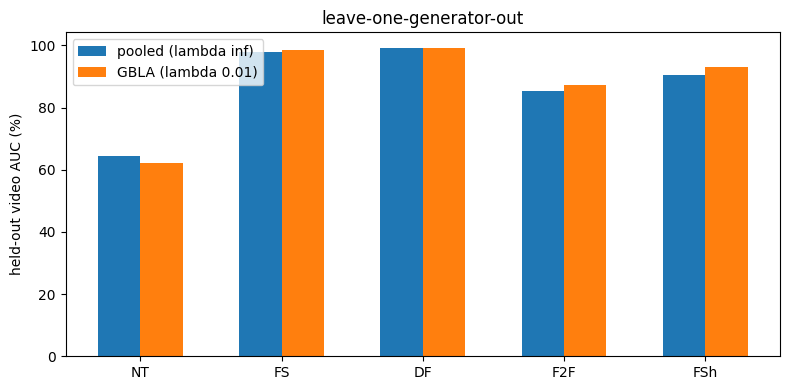

mean held-out gain of GBLA over pooled: +0.55 points


In [10]:
# 5. Leave-one-generator-out table
def records_of(held, lam):
    path = run_dir_for(held, lam) / "results.json"
    if held == "FaceShifter" and not path.exists():
        path = m4_results_path(lam)
    if not path.exists():
        return None
    return json.loads(path.read_text())["test"]


def auc_of(records, name):
    t = pd.DataFrame(records).set_index("test set")
    key = "seen" if name == "seen" else name
    if key not in t.index:
        # M4 names the seen row "seen combined (...)" 
        key = t.index[0] if name == "seen" else name
    return float(t.loc[key, "video AUC"])


rows = []
for held in FOLDS:
    pooled, gbla = records_of(held, float("inf")), records_of(held, 0.01)
    if pooled is None or gbla is None:
        print(f"hold out {SHORT[held]}: not finished")
        continue
    rows.append({
        "held out": SHORT[held],
        "pooled held-out": auc_of(pooled, held),
        "GBLA held-out": auc_of(gbla, held),
        "gain": auc_of(gbla, held) - auc_of(pooled, held),
        "pooled seen": auc_of(pooled, "seen"),
        "GBLA seen": auc_of(gbla, "seen"),
    })
logo = pd.DataFrame(rows).set_index("held out")
if len(logo):
    logo.loc["MEAN"] = logo.mean()
    display(logo.round(2))
    (M5_DIR / "logo.csv").write_text(logo.to_csv())
    fig, ax = plt.subplots(figsize=(8, 4))
    plot_df = logo.drop(index="MEAN", errors="ignore")
    x = np.arange(len(plot_df))
    ax.bar(x - 0.15, plot_df["pooled held-out"], width=0.3, label="pooled (lambda inf)")
    ax.bar(x + 0.15, plot_df["GBLA held-out"], width=0.3, label="GBLA (lambda 0.01)")
    ax.set_xticks(x, plot_df.index)
    ax.set_ylabel("held-out video AUC (%)")
    ax.set_title("leave-one-generator-out")
    ax.legend()
    plt.tight_layout()
    plt.show()
    gain = logo.loc["MEAN", "gain"]
    print(f"mean held-out gain of GBLA over pooled: {gain:+.2f} points")